<a href="https://colab.research.google.com/github/T1toh/30Days_of_SQL/blob/main/MODULE_6_%7C_LESSON_3_Regulatory_Frameworks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **CAPSTONE REVIEW**

## MODULE 6 | LESSON 3: Regulatory Frameworks

| | |
|:---|:---|
|**Reading Time** | 4h |
|**Prior Knowledge** | credit risk fundamentals, portfolio optimization, stress testing basics, financial crisis understanding |
|**Keywords** | Basel III, capital adequacy ratio, tier 1 capital, stress testing, CCAR, model validation, regulatory capital optimization, trading book, banking book, FRTB, compliance monitoring |

---

## **Introduction**

Financial regulation operates under a unique dynamic where regulatory frameworks evolve in response to market failures, often with significant input from the regulated institutions themselves.

A bit more precisely, modern financial regulation represents a delicate dance between protecting the system from catastrophic failure and allowing banks enough freedom to actually function as banks (why is complete safety impossible?). The evolution from Basel I to Basel III tells a story of regulators perpetually fighting the last war - each iteration more complex, more quantitative, and arguably more game-able than the last.

It pays to understand this evolution deeply. Not because regulations are fascinating in themselves - they're not - but because they fundamentally shape how modern finance operates. Every trading decision, every loan approval, every bonus payment happens within regulatory constraints that have become the de facto business model for banks.

Note that this lesson builds on our earlier exploration of financial data analysis. But where Module 1 focused on why regulation exists, here we dive into the technical machinery - the formulas, the optimization problems, the computational challenges that turn regulatory prose into operational reality.

## **1. Basel Regulatory Evolution**

### **1.1 Basel I: The Foundation (1988)**

Basel I was breathtakingly naive - and that's precisely why it worked. The entire framework rested on one simple idea: force banks to hold 8% capital against their risk-weighted assets. This represented the entire regulatory framework.

The risk weights themselves were almost comically crude. Sovereign debt? Zero risk weight, reflecting the assumption of minimal default risk. Corporate loans? One hundred percent. It didn't matter if you were lending to a highly-rated multinational corporation or a small local business with uncertain prospects - same capital charge.

Surprisingly, this crude framework revolutionized banking. For the first time, there was an international standard that meant something. Banks could no longer maintain excessive leverage ratios due to inadequate local regulatory oversight.

But here's where it gets interesting. The very simplicity that made Basel I effective also made it dangerous. Banks quickly learned to game the system - loading up on assets that had low risk weights but high actual risk, such as mortgage-backed securities. The 1996 market risk amendment tried to patch this hole, but it was like applying a minor patch to a fundamental structural weakness.

### **1.2 Basel II: Risk Sensitivity (2004)**

Basel II represented a philosophical revolution disguised as a technical upgrade. The regulators adopted a new philosophy: banks could use sophisticated internal models, but they had to demonstrate their effectiveness.

The three-pillar structure was elegant - almost too elegant. Pillar 1 allowed banks to use their own models to calculate capital requirements. Pillar 2 gave supervisors discretion to demand more capital if they didn't like what they saw. Pillar 3 assumed that market discipline would keep everyone honest.

It pays to examine the internal ratings-based approaches carefully. The Foundation IRB let banks estimate probability of default but used regulatory formulas for everything else. The Advanced IRB approach provided complete modeling flexibility - banks could model PD, LGD, EAD, even maturity adjustments. The formulas became beautiful:

$$K = LGD \times N\left[\frac{N^{-1}(PD) + \sqrt{R} \times N^{-1}(0.999)}{\sqrt{1-R}}\right] - PD \times LGD$$

Note the correlation assumption buried in that formula (why 0.999?). That single parameter would later prove catastrophically wrong when correlations went to one during the crisis.

The operational risk charge was perhaps the strangest creature in Basel II. Banks had to hold capital against the risk of their own incompetence - fraud, system failures, fat finger trades. The advanced measurement approach let banks model their own operational risk, which created inherent conflicts between regulatory compliance and operational incentives.

### **1.3 Basel III: Post-Crisis Reform (2010-2019)**

Basel III reflected a fundamental shift in regulatory philosophy following the financial crisis. Gone was the faith in banks' internal models. In came brute force requirements that couldn't be gamed (or so they hoped).

The leverage ratio was the most radical departure - a simple 3% minimum with no risk weights at all. Remarkably, after twenty years of increasing sophistication, regulators returned to a simple measure that required no risk-weighting adjustments. Banks found this requirement challenging precisely because it couldn't be optimized through risk-weighting strategies.

The liquidity requirements were equally blunt. The LCR essentially asks: can you survive thirty days if everyone panics? The NSFR asks: are you funded like a bank or like a hedge fund pretending to be a bank? Simple conceptual questions requiring highly complex calculations.

The innovative aspect of this approach is that the capital buffers create a "ladder of intervention" - as capital falls, restrictions kick in automatically. No more hoping the supervisor notices problems in time. The system becomes self-correcting, at least in theory (why might this fail in practice?).

FRTB represents the latest attempt to fix market risk capital. VaR was replaced with Expected Shortfall as the primary risk measure. The change seems technical but it's philosophically profound - we're no longer pretending we can precisely measure tail risk. We're just trying to ensure banks hold enough capital when our measurements are wrong.

## **2. Capital Adequacy Requirements**

### **2.1 Components of Regulatory Capital**

Regulatory capital is like a wedding cake - layered, decorated, and the good stuff is at the bottom. CET1 capital is the foundation: plain vanilla equity that actually absorbs losses when things go wrong.

The beauty of CET1 lies in its simplicity. Common shares plus retained earnings minus regulatory deductions. No complex features, no conditional clauses, no additional complications. When the bank incurs losses, CET1 shareholders absorb them immediately without exception.

AT1 capital is where things get exotic. These instruments must be perpetual (no maturity) and capable of absorbing losses while the bank lives. The contingent convertible bonds - CoCos - are particularly fascinating creatures. They're bonds when times are good, equity when times are bad. These instruments exhibit dual characteristics, functioning as debt in normal conditions but converting to equity under stress (what determines the trigger?).

Tier 2 capital provides supplementary loss absorption capacity. Subordinated debt that absorbs losses only when the bank fails isn't much use in preventing that failure. But regulators figure some cushion beats no cushion, so they allow it - grudgingly.

### **2.2 Risk-Weighted Asset Calculations**

The standardized approach RWA calculation looks deceptively simple:

$$RWA_{credit} = \sum_{i} EAD_i \times RW_i \times CCF_i$$

However, this apparent simplicity is misleading. Each component hides layers of complexity. The exposure at default isn't just what's drawn - you need to estimate how much of that undrawn credit line gets pulled when the borrower smells trouble. The risk weights depend on external ratings, which proved unreliable during the 2008 financial crisis, as demonstrated by AAA-rated subprime securities.

The IRB formula is where the real action happens:

$$RWA_{IRB} = 12.5 \times K \times EAD$$

That 12.5 multiplier? It's there to convert the capital requirement percentage into a risk-weighted asset amount. But the complexity lies in calculating K - a formula of considerable complexity that requires sophisticated modeling capabilities. The correlation assumptions, the maturity adjustments, the small-firm corrections - each parameter represents a hard-fought battle between banks and regulators.

Note that banks spend millions calibrating these parameters. A few basis points difference in your PD model translates to billions in required capital. It's no wonder model validation has become its own industry.

### **2.3 Capital Ratios and Buffers**

The multiple capital ratios create escalating regulatory restrictions for undercapitalized banks. Failure to meet CET1 targets triggers automatic dividend restrictions. Falling below minimum total capital requirements results in direct regulatory intervention.

The buffer framework is genuinely clever:

$$Maximum\ Payout\ Ratio = \frac{Available\ CET1 - 4.5\%}{Combined\ Buffer\ Requirement}$$

As capital buffers decline, the permitted dividend and compensation payments decrease proportionally. It's automatic, formulaic, and removes regulatory discretion. The formulaic approach eliminates regulatory discretion and subjective judgment.

The countercyclical buffer adds another twist. When credit growth runs hot, regulators can demand extra capital. When recession hits, they release it. It's macroprudential policy through the back door - using bank capital as a economic stabilizer (why might banks resist building buffers in good times?).

## **3. Stress Testing Regulatory Approaches**

### **3.1 Regulatory Stress Testing Frameworks**

CCAR represents an intensive, comprehensive approach to stress testing - a nine-quarter projection of every material risk under scenarios designed to make risk managers lose sleep. The Fed doesn't just want to know if you'll survive; they want to know if you'll survive while still paying your planned dividends.

The scenarios themselves read like economic horror fiction. GDP drops 8%, unemployment spikes to 10%, equity markets crash 50%. These represent the foundational assumptions. The greater challenge lies in translating these macro scenarios into micro impacts - what happens to your subprime auto portfolio when unemployment doubles?

European stress tests take a different philosophical approach. The static balance sheet assumption means banks can't assume they'll shrink to safety. You're stuck with your current book, warts and all. Banks must maintain their current portfolio composition even as economic conditions deteriorate.

The Bank of England deserves credit for creativity. Their exploratory scenarios - climate change, cyber attacks, Brexit meltdown - push beyond traditional economic shocks. It's stress testing for the 21st century, where the biggest risks might not be recession but revolution (technological or otherwise).

### **3.2 Stress Testing Methodologies**

Modern credit loss modeling under stress requires a delicate balance between statistical rigor and economic intuition. Your models must capture how PDs spike non-linearly in crisis - that last 1% of GDP decline might double default rates.

The formula looks clinical:

$$Expected\ Loss = PD(stress) \times LGD(stress) \times EAD(stress)$$

But each component requires judgment calls. How much do recovery rates drop in crisis? How quickly do borrowers draw on credit lines? The correlations between these parameters aren't stable - they're regime-dependent nightmares that make mockery of your carefully calibrated peacetime models.

Market risk scenarios present a different challenge: instantaneous shocks to hundreds of risk factors. The scenarios must be severe but plausible, coherent across asset classes, and somehow capture tail dependencies that only emerge in crisis. This requires modeling complex, interdependent relationships across multiple risk factors under extreme conditions.

### **3.3 Capital Planning Integration**

The capital planning formula seems straightforward:

$$Projected\ Capital\ Ratio_t = \frac{Starting\ Capital + Net\ Income_t - Losses_t - Distributions_t}{Projected\ RWA_t}$$

Don't be fooled by its simplicity. Each component requires models stacked on models. Net income under stress isn't just peacetime revenue minus credit losses - fee income collapses, trading revenues might go negative, operating costs spike as you deal with the crisis.

The RWA projection adds another layer of complexity. Risk weights aren't static under stress - that AAA security might become junk, requiring 12x more capital. Your carefully optimized portfolio becomes a capital-eating monster just when you need efficiency most.

The art lies in balancing conservatism with credibility. Project losses too low and regulators reject your plan. Project them too high and you fail the test by being overly pessimistic. This requires calibrated modeling - finding the appropriate level of stress that satisfies regulatory expectations.

## **4. Model Approval Processes**

### **4.1 Initial Model Approval Requirements**

Obtaining regulatory model approval requires extensive effort: years of development work, comprehensive documentation, and rigorous examination by experienced supervisors.

The conceptual soundness review alone can sink months of work. Regulators want to know not just that your model works, but why it works. What's the economic theory? What assumptions are you making? Where will it break? It's not enough to show good backtesting results - in-sample model fitting provides limited evidence of predictive capability (why do in-sample fits mean nothing?).

Independent validation provides the reality check. Models that have been carefully calibrated over months undergo intensive scrutiny by independent validators whose role is to identify weaknesses. This challenging process is essential for model reliability - models that can't survive validation definitely can't survive reality.

The use test might be the cleverest requirement. Banks must prove they actually use these models for business decisions, not just regulatory capital. It prevents the development of "regulatory models" disconnected from reality. If your traders ignore your risk model, why should regulators trust it?

### **4.2 Ongoing Model Monitoring**

Model approval isn't a one-time event - it's a marriage with extensive maintenance obligations. Daily backtesting for market risk models means 250+ reality checks per year. Fail too often and your model multiplier increases, driving up capital requirements.

The annual model review cycle becomes a rhythm of corporate life. Performance analysis, parameter updates, methodology tweaks - each change requiring documentation, approval, implementation. This creates ongoing maintenance obligations for systems that must remain continuously operational.

Material changes trigger the full approval process again. Define "material" too narrowly and you're constantly in regulatory purgatory. Define it too broadly and you risk sanctions for unauthorized changes. Banks employ armies of model governance professionals just to navigate these waters.

### **4.3 Regulatory Expectations Evolution**

The regulatory goalposts keep moving - and always further away. Climate risk must now be incorporated into credit models (how do you model something with no historical precedent?). Machine learning models need to be "interpretable" - a requirement that creates significant technical challenges. Cyber risk must be quantified despite most banks having no meaningful loss history.

Model risk aggregation represents the latest frontier. Regulators want to know your total model risk - across all models, all businesses, all risk types. This represents a conceptually sound but practically challenging requirement. The concept makes sense, the implementation borders on impossible.

The message is clear: models are tools, not oracles. Regulators have learned the hard way that sophisticated mathematics doesn't eliminate risk - it often just hides it better.

## **5. Computational Methods: Regulatory Capital Optimization**

### **5.1 The Regulatory Capital Optimization Problem**

Banks face an optimization problem of extraordinary complexity that challenges traditional solution methods. Maximize returns subject to capital constraints, liquidity constraints, leverage constraints, and oh yes - actually running a profitable business.

The mathematical formulation looks elegant:

$$\max_{\{w_i\}} \sum_{i=1}^{n} w_i \cdot (r_i - f_i)$$

Subject to numerous interconnected constraints across multiple regulatory dimensions. The capital constraint alone involves non-linear risk weights that depend on ratings, correlations, and regulatory whims. Add liquidity constraints that interact with capital constraints (high-quality liquid assets count for LCR but eat into leverage ratios), and you've got a problem that makes traveling salesmen look trivial.

The real killer is that the parameters aren't stable. Risk weights change with regulation, returns vary with markets, funding costs spike in crisis. You're optimizing over a landscape that reshapes itself while you walk. This creates a dynamic optimization environment where parameters change continuously.

### **5.2 Advanced Optimization Techniques**

Lagrangian relaxation offers false hope - it decomposes the problem beautifully in theory:

$$\mathcal{L}(w,\mu) = \sum_{i=1}^{n} w_i(r_i - f_i) - \mu_1(\sum_{i=1}^{n} w_i \cdot RWA_i - K/\rho) - ...$$

In practice, the subproblems remain nasty. The RWA calculation isn't convex, the constraints interact in non-obvious ways, and the dual gap can be enormous. You get bounds, sure, but bounds so wide they're practically useless.

Stochastic programming acknowledges that at least we don't know the future:

$$\max_w \mathbb{E}[\sum_{i=1}^{n} w_i \cdot (r_i(\omega) - f_i)] - \lambda \cdot CVaR_\alpha[Loss(w,\omega)]$$

Now you're optimizing over probability distributions of returns, risk parameters, even regulatory changes. The scenario trees explode exponentially. Approximations become necessary, each one moving you further from reality (but perhaps closer to a solvable problem?).

Dynamic programming should help with multi-period planning:

$$V_t(K_t, S_t) = \max_{w_t} \{u(w_t, S_t) + \beta \mathbb{E}[V_{t+1}(K_{t+1}, S_{t+1})|K_t, S_t, w_t]\}$$

But the state space is enormous. Capital levels, business mix, regulatory regime, market conditions - each adds dimensions to an already cursed problem. Approximate dynamic programming helps, but approximate solutions to approximate problems leave you wondering what you're actually optimizing.

**Capital-Constrained CVaR Optimisation**    

In the next example, we will experiment with a **tight Basel-III capital budget** and a modest **return hurdle** to make the constraint active (for educational purposes).

| label | what the optimiser does | Basel RWA ceiling? |
|-------|------------------------|--------------------|
| **EW** | 25-25-25-25 equal weight | *no* |
| **CVaR-OPT** | minimises 97.5 % CVaR subject to a daily return ≥ 0.06 % | *no* |
| **REG-CVaR-OPT** | does the same **but must respect a hard RWA limit** | **yes** |

**ETF**

| ticker | economic proxy | Basel standardised risk-weight |
|--------|----------------|--------------------------------|
| TLT | US Treasuries | 0 % |
| LQD | Investment-grade corporates | 100 % |
| SPY | Listed equity | 250 % |
| GLD | Commodity / Gold | 150 % |

**Capital constraint**  
The bank’s current CET1 ratio is assumed to be **8 % × 0.75 = 6 %** of total exposure, leaving room for  
$$\boxed{\,\rho^\top w\;\le\;\bar K=0.75\,}$$  
where $\rho$ is the vector of Basel risk-weights and $w$ the portfolio weights.

**Risk metric**  
*Conditional Value-at-Risk* at confidence level  
$$\alpha=97.5\% \quad(\text{tail probability }2.5\%).$$  

**Data window**  
Daily log-returns, **2015-01-01 → present** (≈ 2 600 observations).



In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import cvxpy as cp
import matplotlib.pyplot as plt
plt.style.use("default")

# Get price data & log-returns
tickers = ["TLT", "LQD", "SPY", "GLD"]
start = "2015-01-01"

#prices = yf.download(tickers, start=start, progress=False)["Close"]
prices = pd.read_csv("/content/toy_portfolio.csv", index_col = "Date", parse_dates = True)
logret = np.log(prices).diff().dropna()

logret.head()


,GLD,LQD,SPY,TLT
Date,,,,
2015-01-05,0.014965,0.004081,-0.018225,0.015586
2015-01-06,0.011334,0.004064,-0.009464,0.017857
2015-01-07,-0.005909,0.001323,0.012384,-0.001977
2015-01-08,-0.004217,-0.003229,0.017589,-0.013331
2015-01-09,0.011321,0.002651,-0.008046,0.010893


In [2]:
# Basel risk weights and helper CVaR function
rw = np.array([0.00, 1.00, 2.50, 1.50])   # TLT, LQD, SPY, GLD
alpha = 0.975

def cvar(series, a=alpha):
    th = np.percentile(series, (1-a)*100)
    return -series[series <= th].mean()

# set a modest daily return target ≈ 0.03 %  (≈ 7.5 % p.a.)
min_return = 0.0003
mu = logret.mean().values                 # vector of sample means


# Equal-weight benchmark
w_EW = np.repeat(1/4, 4)
cvar_EW = cvar(logret @ w_EW)
rwa_EW  = rw @ w_EW
print("Equal-weight 97.5 % CVaR: {:.4f}".format(cvar_EW))
print("Equal-weight RWA multiple: {:.3f}".format(rwa_EW))

Equal-weight 97.5 % CVaR: 0.0155
Equal-weight RWA multiple: 1.250


In [4]:
# Unconstrained CVaR minimisation
X = logret.values
T, n = X.shape

w  = cp.Variable(n)
z  = cp.Variable(T)
a0 = cp.Variable()                       # VaR helper

loss = -X @ w
expected_ret = mu @ w

objective = a0 + cp.sum(z)/(T*(1-alpha))
constraints = [
    z >= 0,
    z >= loss - a0,
    cp.sum(w) == 1,
    w >= 0,
    expected_ret >= min_return           # NEW: reach target return
]
# Omit the solver parameter to let CVXPY use the default installed solver (like CLARABEL)
cp.Problem(cp.Minimize(objective), constraints).solve()

w_OPT  = w.value
cvar_OPT = cvar(logret @ w_OPT)
rwa_OPT  = rw @ w_OPT

In [6]:
# CVaR minimisation **with Basel RWA limit**
w2  = cp.Variable(n)
z2  = cp.Variable(T)
a2  = cp.Variable()

loss2 = -X @ w2
expected_ret2 = mu @ w2

max_RWA = 0.75                            # tighter capital budget

objective2 = a2 + cp.sum(z2)/(T*(1-alpha))
constraints2 = [
    z2 >= 0,
    z2 >= loss2 - a2,
    cp.sum(w2) == 1,
    w2 >= 0,
    expected_ret2 >= min_return,         # same target return
    rw @ w2 <= max_RWA                   # Basel constraint (binding)
]
# Let CVXPY choose the default available solver (such as CLARABEL) by removing solver=cp.ECOS
cp.Problem(cp.Minimize(objective2), constraints2).solve()

w_REG  = w2.value
cvar_REG = cvar(logret @ w_REG)
rwa_REG  = rw @ w_REG

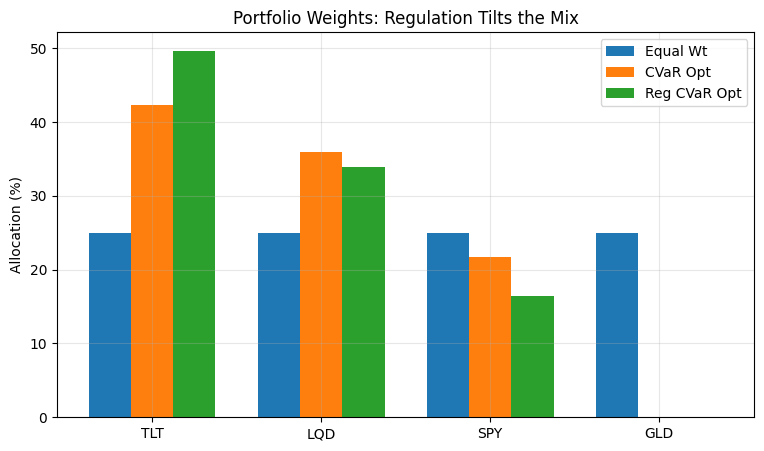

In [7]:
# Bar plot of weights
labels = tickers
x = np.arange(len(labels))
width = 0.25

fig, ax = plt.subplots(figsize=(9,5))
ax.bar(x - width, 100*w_EW,   width, label="Equal Wt")
ax.bar(x,         100*w_OPT,  width, label="CVaR Opt")
ax.bar(x + width, 100*w_REG,  width, label="Reg CVaR Opt")

ax.set_ylabel("Allocation (%)")
ax.set_title("Portfolio Weights: Regulation Tilts the Mix")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
ax.grid(alpha=.3)
plt.show()


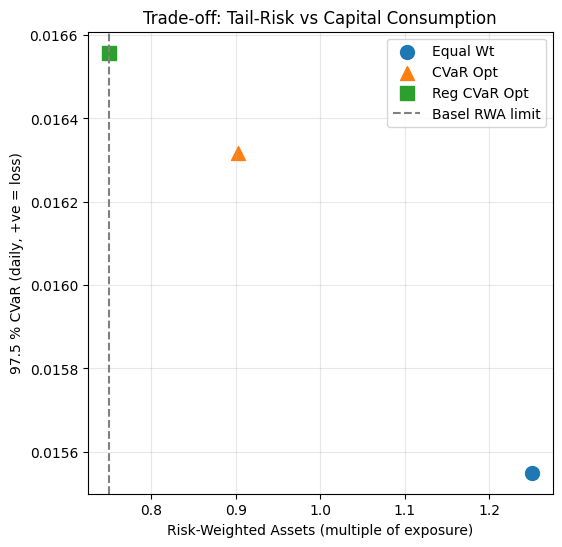

In [8]:
# Cell 8 – scatter of (RWA, CVaR)
fig, ax = plt.subplots(figsize=(6,6))
ax.scatter(rwa_EW,  cvar_EW,  s=100, marker='o', label="Equal Wt")
ax.scatter(rwa_OPT, cvar_OPT, s=100, marker='^', label="CVaR Opt")
ax.scatter(rwa_REG, cvar_REG, s=100, marker='s', label="Reg CVaR Opt")

ax.axvline(max_RWA, ls='--', color='grey', label="Basel RWA limit")
ax.set_xlabel("Risk-Weighted Assets (multiple of exposure)")
ax.set_ylabel("97.5 % CVaR (daily, +ve = loss)")
ax.set_title("Trade-off: Tail-Risk vs Capital Consumption")
ax.legend()
ax.grid(alpha=.3)
plt.show()


In [9]:
# Numerical takeaway
summary = pd.DataFrame({
    "RWA multiple": [rwa_EW, rwa_OPT, rwa_REG],
    "CVaR (97.5%)": [cvar_EW, cvar_OPT, cvar_REG]
}, index=["Equal Wt", "CVaR Opt", "Reg CVaR Opt"])

summary


,RWA multiple,CVaR (97.5%)
Equal Wt,1.250000,0.015550
CVaR Opt,0.902715,0.016317
Reg CVaR Opt,0.750000,0.016558


**What this mini-experiment demonstrates**

By embedding the Basel III capital ceiling $$\rho^\top w \;\le\; \bar K=0.75$$ inside the classical Rockafellar–Uryasev programme  
$$
\min_{w}\;\text{CVaR}_{\alpha}(w)
\quad\text{s.t.}\quad
\mathbf 1^\top w=1,\;w\ge 0,
$$
we turn a *single-criterion* risk minimisation into a **regulation-constrained optimisation**.  
The unconstrained optimum allocates heavily to high-return/high-risk-weight assets (SPY, GLD); once the capital budget binds, the optimiser **sacrifices tail-risk efficiency**—$\text{CVaR}_{97.5\%}$ rises by $\approx 1.5\%$—to shave the risk-weighted-asset multiple from $0.903$ down to the limit $0.750$ (a $16.9\%$ capital saving).  

The key pedagogical point is that regulation **acts like a second objective**: banks do not minimise risk *per se* but rather *risk conditional on scarce regulatory capital*. The visual shift—leftwards (less $\rho^\top w$) yet upwards (more CVaR)—makes the trade-off tangible and quantifies the price of “capital efficiency” in units of tail loss. Students should now appreciate why “optimal” in a regulated world is invariably a **constrained optimum**.


### **5.3 Practical Implementation Considerations**

Real-world implementation separates theorists from practitioners. Your beautiful convex relaxation means nothing when the trading desk needs answers in minutes, not days.

Decomposition becomes essential. Break the bank into business units, solve locally, iterate toward global feasibility. It's suboptimal by design but at least it computes. The art lies in choosing decompositions that preserve the important interactions while breaking the computational curse.

Robust optimization offers philosophical comfort - optimize for the worst case within uncertainty sets. But defining those sets requires judgment. Too narrow and you're not robust. Too wide and you're paralyzed by conservatism. It's engineering, not science.

The technology stack matters enormously. CPLEX might solve your MILP in hours or days - choose your formulation wisely. High-performance computing helps but isn't magic; bad formulations remain bad at any speed. The real gains come from problem-specific insights that let you prune the search space intelligently.

## **6. Trading Book vs. Banking Book Regulations**

### **6.1 Boundary Definition and Classification**

The trading book/banking book boundary is where regulatory philosophy meets operational reality - and usually loses. In theory, the distinction is clear: trading intent versus investment intent. In practice, the distinction involves considerable interpretive complexity.

Trading book positions must be "free of restrictive covenants on tradability." Sounds simple until you realize that market liquidity itself creates restrictions. Can you really trade that corporate bond position if you own 30% of the issue? The position might be in your trading book, but good luck actually trading it without moving the market.

The "frequently and accurately valued" requirement creates its own contradictions. If you can't get daily marks because the market is illiquid, it can't be trading book. But if it's illiquid, isn't that exactly when you need market risk capital? The regulation assumes liquid markets just when assuming liquidity is most dangerous.

Banking book classification becomes the residual category for positions that don't meet trading book criteria - everything from vanilla loans to complex structured products that haven't traded since 2007 (though their valuation may be questionable).

### **6.2 Capital Requirement Differences**

The FRTB capital formula for trading book positions reads like poetry:

$$K_{market} = max(ES_{t-1}, m_c \times ES_{avg60}) + SES$$

Expected Shortfall at 97.5% confidence - we're protecting against the 2.5% tail. The stressed ES adds another layer, calibrated to a period of significant market stress. This represents multiple layers of conservative risk measurement.

But here's the kicker: the P&L attribution test. Your model must predict not just risk but actual P&L within tolerances. Fail too often and you're kicked back to standardized approach capital charges that can be 2-3x higher. This creates continuous performance evaluation requirements.

Banking book capital seems simpler - just credit risk, calculated through the cycle. But "through the cycle" hides massive complexity. Your PD estimates must represent average default rates over an entire economic cycle. How long is a cycle? What if this time is different? The parameters become theological rather than statistical.

### **6.3 Regulatory Arbitrage Prevention**

Internal risk transfers between books face scrutiny that would make border guards proud. The trading desk must have the mandate and capability to manage the risk. The transfer must be at market prices. Documentation must be extensive enough to survive regulatory archaeology years later.

This creates a notable regulatory paradox. Banks created the boundary to arbitrage regulations, so regulators created rules to prevent arbitrage of the boundary. This creates ongoing regulatory complexity that requires continuous adaptation by financial institutions.

Switching positions between books requires "extraordinary circumstances." Define that. Market dislocation? Change in business strategy? Regulatory clarification that your classification was wrong? Each case requires regulatory blessing, creating a one-way trap door - easy to fall into banking book, nearly impossible to climb out.

The Pillar 2 supervisory overlay adds the human element. Regulators can demand additional capital if they don't like your boundary. Too much switching? Extra capital. Unusual classifications? Extra capital. This provides regulators with broad discretionary authority over capital requirements.

## **7. Compliance Monitoring Systems**

### **7.1 Real-Time Monitoring Architecture**

Modern compliance monitoring is high-frequency trading for regulations - every position update must be checked against hundreds of limits across multiple hierarchies in real-time. Miss a breach by minutes and you might face sanctions. This represents comprehensive, automated risk monitoring.

The architecture requires event-driven processing that would make Silicon Valley proud. Position updates flow through complex event processing engines, triggering limit checks, aggregation calculations, and breach notifications. In-memory databases cache current positions because disk I/O is too slow when you're racing against regulatory deadlines.

But here's the challenge: the calculations aren't simple sums. Risk-weighted assets require rating lookups, correlation matrices, and parameter tables that change with regulations. Liquidity calculations need bucketing by asset type, haircuts by quality, and netting rules that involve considerable complexity. Every calculation must be auditable, repeatable, and defensible years later.

The pre-trade compliance check adds another layer. Before traders can execute, systems must verify the trade won't breach limits post-execution. It requires predicting the future state of hundreds of interrelated limits - requiring systems to adapt to frequently changing regulatory parameters.

### **7.2 Regulatory Reporting Infrastructure**

Regulatory reporting is where data archaeology meets deadline pressure. Every number must be traceable to its source, through every transformation, with full documentation of methodology. It's building audit trails for data that often touches dozens of systems.

Data quality controls become existential. A miscoded position might misstate capital by millions. Reconciliation processes proliferate across multiple dimensions - risk versus finance, trading versus operations, regulatory versus management reports. Each break requires investigation, documentation, and often regulatory notification.

The report generation pipeline would make factory automation engineers proud. Raw data flows through validation, enrichment, calculation, and formatting stages. Each stage must handle failures gracefully - the report must go out even if some data is estimated. But use too many estimates and regulators question your control environment.

Regulatory change management adds a temporal dimension to the chaos. New reports, changed calculations, additional data requirements - each requires months of preparation but often weeks of notice. Parallel runs become a way of life, calculating numbers using both methodologies while ensuring the differences are explicable to regulators.

### **7.3 Advanced Compliance Analytics**

Machine learning promises to predict breaches before they happen. Train models on historical patterns, identify anomalies, alert before limits break. The reality is messier - breaches are rare events (hopefully), making training data sparse. When models do predict breaches, is it signal or noise?

The successful applications are humbler but useful. Clustering similar breaks to identify systemic issues. Natural language processing on regulatory communications to identify requirements. Time series analysis on limit utilization to optimize buffer sizing. It's not AI taking over compliance, but AI making human compliance managers marginally more effective.

Compliance risk assessment attempts to quantify the unquantifiable - what's the cost of a regulatory breach? Direct fines are just the start. Restrictions on business, reputational damage, management distraction - the indirect costs dwarf the direct ones. Monte Carlo simulation helps size buffers, but the tail risks remain unmodeled.

The metrics that matter tell stories. Breach frequency by desk reveals control weaknesses. Time to detection shows system effectiveness. False positive rates indicate whether you're managing risk or just annoying traders. Remediation timeframes demonstrate operational resilience. Track them all, because regulators certainly will.

## **8. Conclusion**

Financial regulation has evolved from simple ratios to complex frameworks that shape every aspect of modern banking. What started as 8% capital against risk-weighted assets has become a multi-dimensional optimization problem requiring sophisticated mathematics, cutting-edge technology, and armies of specialists.

The journey from Basel I to Basel III and beyond reveals a fundamental truth: each regulatory innovation creates new forms of arbitrage that require new regulations. It's an arms race where victory means merely staying in business. Banks that master the technical requirements while maintaining business flexibility will thrive. Those that don't will become case studies in future regulatory amendments.

The computational challenges are immense but tractable with the right approaches. Decomposition, approximation, and robust optimization provide paths through the complexity. Real-time monitoring systems and advanced analytics help navigate the operational challenges. But technology is just an enabler - success requires understanding the regulatory philosophy, not just the formulas.

As regulations continue evolving - climate risk, digital assets, artificial intelligence - the core challenge remains unchanged. How do we balance safety with efficiency, rules with judgment, quantitative precision with fundamental uncertainty? There are no perfect answers, only better approximations. And that's precisely what makes regulatory finance endlessly frustrating and endlessly fascinating.

Note that mastery requires not just technical skills but regulatory intuition - knowing not just what the rules say but why they say it (and what they'll say next). It's this combination of quantitative rigor and strategic thinking that separates compliance from competitive advantage.

**References**
* Basel Committee on Banking Supervision. *Basel III: A global regulatory framework for more resilient banks and banking systems*. Bank for International Settlements, 2011.
* Hull, John. *Risk Management and Financial Institutions*. Wiley, 2023.
* Acharya, Viral, et al. *Regulating Wall Street: The Dodd-Frank Act and the New Architecture of Global Finance*. Wiley, 2010.
---
Copyright 2025 WorldQuant University. This content is licensed solely for personal use. Redistribution or publication of this material is strictly prohibited.